Matplotlib is building the font cache; this may take a moment.


[0]	validation_0-NormalDistribution-NLL:3.91412
[1]	validation_0-NormalDistribution-NLL:3.89893
[2]	validation_0-NormalDistribution-NLL:3.88372
[3]	validation_0-NormalDistribution-NLL:3.87085
[4]	validation_0-NormalDistribution-NLL:3.85981
[5]	validation_0-NormalDistribution-NLL:3.84928
[6]	validation_0-NormalDistribution-NLL:3.83932
[7]	validation_0-NormalDistribution-NLL:3.83023
[8]	validation_0-NormalDistribution-NLL:3.82024
[9]	validation_0-NormalDistribution-NLL:3.81296
[10]	validation_0-NormalDistribution-NLL:3.80440
[11]	validation_0-NormalDistribution-NLL:3.79717
[12]	validation_0-NormalDistribution-NLL:3.78947
[13]	validation_0-NormalDistribution-NLL:3.78043
[14]	validation_0-NormalDistribution-NLL:3.77293
[15]	validation_0-NormalDistribution-NLL:3.76589
[16]	validation_0-NormalDistribution-NLL:3.75988
[17]	validation_0-NormalDistribution-NLL:3.75499
[18]	validation_0-NormalDistribution-NLL:3.74723
[19]	validation_0-NormalDistribution-NLL:3.74128
[20]	validation_0-NormalDistri

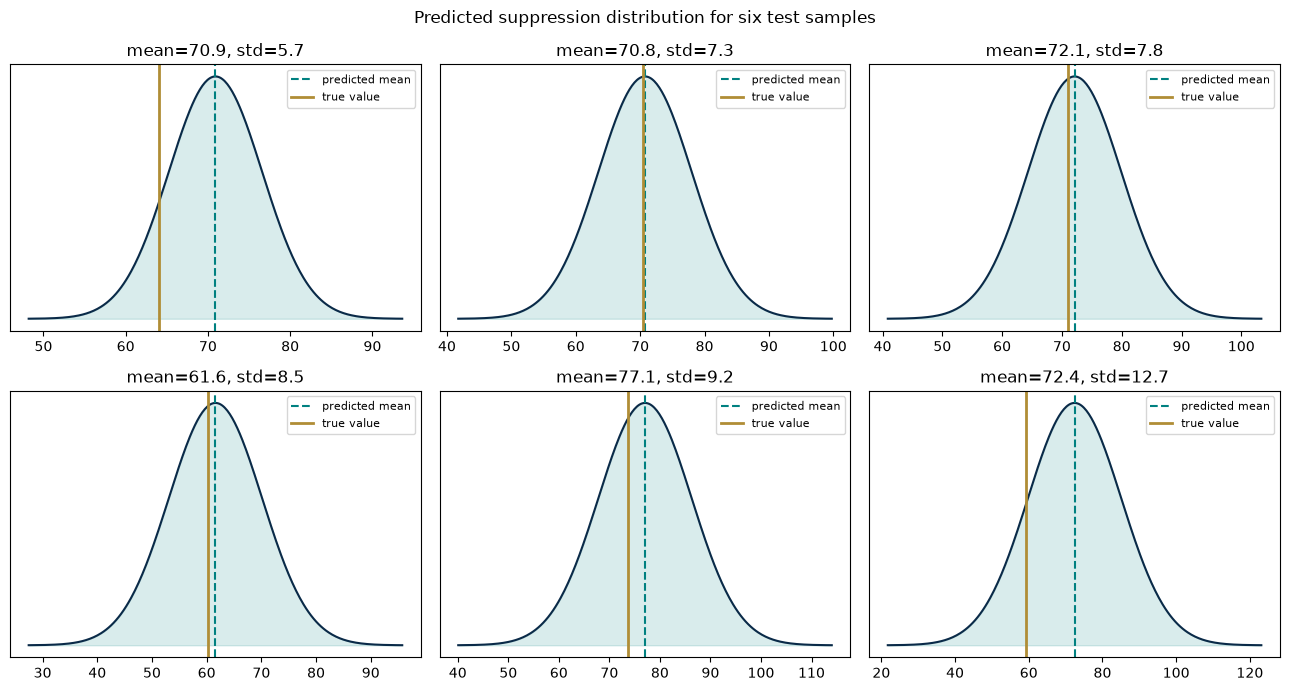

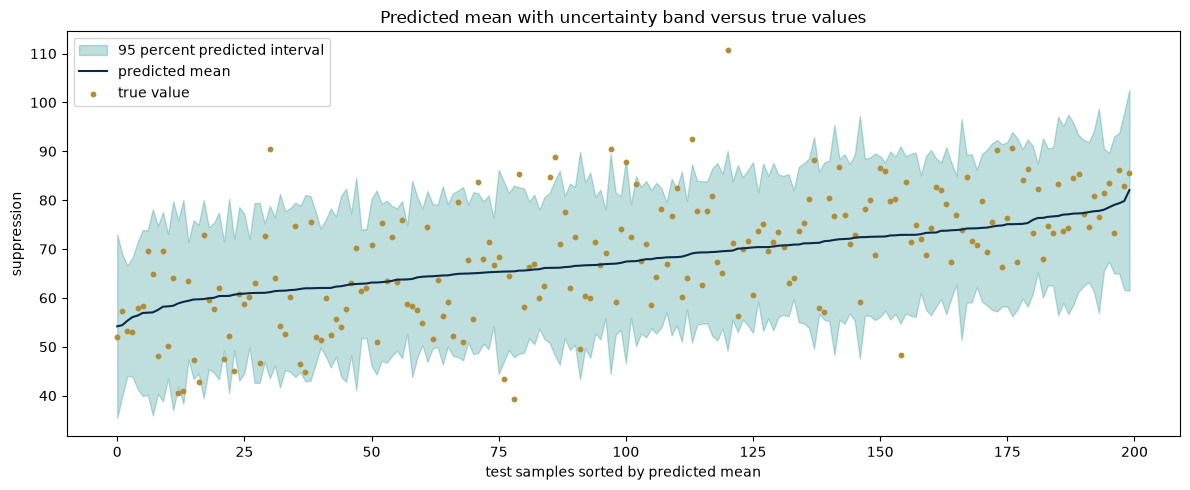

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from xgboost_distribution import XGBDistribution


def make_dummy_data(n_samples=800, n_nutrients=8, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, size=(n_samples, n_nutrients))
    weights = rng.normal(0.0, 1.0, size=n_nutrients)
    signal = 50.0 + 18.0 * (X @ weights) + 12.0 * np.sin(3.0 * X[:, 0])
    noise_scale = 3.0 + 9.0 * X[:, 1]
    y = signal + rng.normal(0.0, noise_scale)
    return X, y


X, y = make_dummy_data()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

model = XGBDistribution(
    distribution="normal",
    n_estimators=500,
    early_stopping_rounds=20,
    max_depth=3,
    learning_rate=0.05,
)
model.fit(X_train, y_train, eval_set=[(X_test, y_test)])

preds = model.predict(X_test)
mean, std = preds.loc, preds.scale


fig1, axes = plt.subplots(2, 3, figsize=(13, 7))
idx = np.argsort(std)[np.linspace(0, len(std) - 1, 6).astype(int)]
for ax, i in zip(axes.ravel(), idx):
    grid = np.linspace(mean[i] - 4 * std[i], mean[i] + 4 * std[i], 300)
    ax.plot(grid, norm.pdf(grid, mean[i], std[i]), color="#0a2a48")
    ax.fill_between(grid, norm.pdf(grid, mean[i], std[i]), alpha=0.15, color="#008080")
    ax.axvline(mean[i], color="#008080", linestyle="--", label="predicted mean")
    ax.axvline(y_test[i], color="#b08d36", linewidth=2, label="true value")
    ax.set_title(f"mean={mean[i]:.1f}, std={std[i]:.1f}")
    ax.set_yticks([])
    ax.legend(fontsize=8)
fig1.suptitle("Predicted suppression distribution for six test samples")
fig1.tight_layout()
fig1.savefig("xgbdist_per_sample.png", dpi=120)


fig2, ax = plt.subplots(figsize=(12, 5))
order = np.argsort(mean)
xs = np.arange(len(order))
m = mean[order]
s = std[order]
ax.fill_between(xs, m - 1.96 * s, m + 1.96 * s, alpha=0.25, color="#008080",
                label="95 percent predicted interval")
ax.plot(xs, m, color="#0a2a48", label="predicted mean")
ax.scatter(xs, y_test[order], s=10, color="#b08d36", label="true value")
ax.set_xlabel("test samples sorted by predicted mean")
ax.set_ylabel("suppression")
ax.set_title("Predicted mean with uncertainty band versus true values")
ax.legend()
fig2.tight_layout()
fig2.savefig("xgbdist_intervals.png", dpi=120)

inside = np.mean((y_test >= mean - 1.96 * std) & (y_test <= mean + 1.96 * std))
print(f"fraction of true values inside the 95 percent interval: {inside:.2f}")
print(f"mean predicted std: {std.mean():.2f}")